# MATH7810 Python for Data Science
## Individual Case Study: Credit Card Default Risk

**Dataset:** Default of Credit Card Clients (uploaded CSV)

This notebook analyses a 1,000-observation sample of credit-card clients. The outcome of interest is whether a client defaults on payment in the following month. The analysis is organised according to the case-study instructions: exploratory data analysis, three research questions with statistical analysis, a human–AI reflection, and references.

> **Important:** The numerical results in this notebook are calculated from the uploaded `DefaultCreditCard.csv`. The reflection section includes one clearly marked item that must be completed with the student's actual Copilot interaction. The student's own three initial research questions should also be checked and edited to reflect the questions genuinely considered before using AI, as required by the assignment.

### 1.1 Introduction to the data set

According to the dataset documentation, this dataset contains information on default payments, demographic factors, credit data, payment history, and bill statements of credit-card clients in Taiwan from **April 2005 to September 2005**. Each row represents one client, and the dataset contains **25 variables**.

The variables cover:
- **Client and demographic information:** `ID`, `SEX`, `EDUCATION`, `MARRIAGE`, and `AGE`.
- **Credit information:** `LIMIT_BAL`, the amount of credit given in **New Taiwan dollars (NT dollars)**.
- **Repayment history:** `PAY_0`, `PAY_2`, `PAY_3`, `PAY_4`, `PAY_5`, and `PAY_6`, recording repayment status from September to April 2005.
- **Bill statements:** `BILL_AMT1` to `BILL_AMT6`, measured in NT dollars.
- **Previous payments:** `PAY_AMT1` to `PAY_AMT6`, also measured in NT dollars.
- **Outcome:** `default.payment.next.month`, where 1 means default and 0 means no default.

The repayment-status codes are not ordinary continuous measurements. In the documentation, -1 means payment duly, while 1, 2, and higher positive values indicate delays of one month, two months, and so on (with 9 meaning nine months or more). The documentation does not define the meaning of code 0, so this report retains it as a separate recorded value and avoids assigning it an interpretation.

The outcome variable, `default.payment.next.month`, is the main response variable. `ID` is an identifier and is excluded from statistical modelling. The demographic codes `SEX`, `EDUCATION`, and `MARRIAGE` are categorical variables, even though they are stored numerically. Monetary values are expressed in NT dollars, not an unspecified currency. The uploaded CSV is the actual analysis sample used in this report; its dimensions and missing values are checked below.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from IPython.display import display

# Read the assigned data file.
df = pd.read_csv("DefaultCreditCard.csv")

target = "default.payment.next.month"
print("Number of rows and columns:", df.shape)
print("\nData types:")
display(df.dtypes.rename("data type").to_frame())
print("\nMissing values by variable:")
display(df.isna().sum().rename("missing values").to_frame())
print("\nFirst five observations:")
display(df.head())

Number of rows and columns: (1000, 25)

Data types:


,data type
ID,int64
LIMIT_BAL,float64
SEX,int64
EDUCATION,int64
MARRIAGE,int64
AGE,int64
PAY_0,int64
PAY_2,int64
PAY_3,int64
PAY_4,int64



Missing values by variable:


,missing values
ID,0
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_0,0
PAY_2,0
PAY_3,0
PAY_4,0



First five observations:


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,30,50000.0,1,1,2,26,0,0,0,0,0,0,15329.0,16575.0,17496.0,17907.0,18375.0,11400.0,1500.0,1500.0,1000.0,1000.0,1600.0,0.0,0
1,64,50000.0,2,2,1,46,0,0,0,-2,-2,-2,28718.0,29166.0,0.0,0.0,0.0,0.0,1000.0,0.0,0.0,0.0,0.0,0.0,1
2,72,320000.0,1,2,2,29,2,2,2,2,2,2,58267.0,59246.0,60184.0,58622.0,62307.0,63526.0,2500.0,2500.0,0.0,4800.0,2400.0,1600.0,1
3,113,280000.0,1,2,1,41,2,2,2,2,2,3,135673.0,138532.0,134813.0,144401.0,152174.0,149415.0,6500.0,0.0,14254.0,14850.0,0.0,5000.0,0
4,133,420000.0,1,2,1,34,0,0,0,0,0,0,253454.0,247743.0,229049.0,220951.0,210606.0,188108.0,9744.0,9553.0,7603.0,7830.0,7253.0,11326.0,0


The uploaded file has **1,000 observations and 25 variables**. The missing-value check shows whether any cleaning for missing data is required. The identifier is retained in the raw data for traceability but is not used as an explanatory variable. No rows are removed simply because a value is unusually large; extreme values may be genuine client records and should not be deleted without a substantive reason.

### Variable definitions from the dataset documentation

| Variable(s) | Meaning |
|---|---|
| `ID` | Client identifier |
| `LIMIT_BAL` | Given credit amount (NT dollars), including individual and family/supplementary credit |
| `SEX` | 1 = male; 2 = female |
| `EDUCATION` | 1 = graduate school; 2 = university; 3 = high school; 4 = others; 5 and 6 = unknown |
| `MARRIAGE` | 1 = married; 2 = single; 3 = others |
| `AGE` | Age in years |
| `PAY_0`, `PAY_2`–`PAY_6` | Repayment status from September to April 2005; -1 = pay duly; positive values indicate months of payment delay; 9 = nine months or above |
| `BILL_AMT1`–`BILL_AMT6` | Monthly bill statement amounts (NT dollars), September to April |
| `PAY_AMT1`–`PAY_AMT6` | Previous payment amounts (NT dollars), September to April |
| `default.payment.next.month` | Next-month default outcome: 1 = yes; 0 = no |

The source documentation explicitly identifies education codes 5 and 6 as unknown. It does not provide a definition for repayment-status code 0; this report does not invent one.

### Variable overview and categorical distributions

In [2]:
categorical_cols = ["SEX", "EDUCATION", "MARRIAGE", target]
for col in categorical_cols:
    print(f"\n{col}")
    display(df[col].value_counts(dropna=False).sort_index().rename("count").to_frame())

print("\nTarget variable proportions:")
display((df[target].value_counts(normalize=True).sort_index() * 100)
        .rename("percentage").to_frame().round(1))


SEX


,count
SEX,
1,397
2,603



EDUCATION


,count
EDUCATION,
1,343
2,479
3,162
4,5
5,10
6,1



MARRIAGE


,count
MARRIAGE,
0,1
1,465
2,526
3,8



default.payment.next.month


,count
default.payment.next.month,
0,784
1,216



Target variable proportions:


,percentage
default.payment.next.month,
0,78.4
1,21.6


For the repayment-status variables, `PAY_0` refers to the most recent repayment status in the file, while `PAY_2` to `PAY_6` refer to earlier months. These variables are coded numerically, but their values describe repayment status rather than ordinary continuous measurements. The education and marriage fields also contain special codes in addition to the main categories; these codes are retained rather than silently recoded.

### 1.2 Numerical descriptive statistics

In [3]:
numeric_cols = [
    "LIMIT_BAL", "AGE",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]
desc = df[numeric_cols].describe().T
desc = desc[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
display(desc.round(2))

print("Default rate:", round(df[target].mean() * 100, 1), "%")
print("Number of default cases:", int(df[target].sum()))
print("Number of non-default cases:", int((df[target] == 0).sum()))

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,1000.0,174080.00,132714.61,10000.0,60000.00,150000.0,250000.00,680000.0
AGE,1000.0,35.41,9.42,21.0,28.00,34.0,41.00,66.0
BILL_AMT1,1000.0,51341.70,74935.41,-9095.0,2902.50,20952.5,68287.75,568532.0
BILL_AMT2,1000.0,49072.57,73301.21,-30000.0,2867.75,20036.5,64871.00,743970.0
BILL_AMT3,1000.0,47890.26,71576.80,-10608.0,2392.75,19600.5,60361.25,577015.0
BILL_AMT4,1000.0,43614.25,65629.76,-6867.0,1879.75,18737.0,57783.75,565669.0
BILL_AMT5,1000.0,40954.36,62095.11,-20006.0,1624.00,18039.5,50708.25,524315.0
BILL_AMT6,1000.0,39809.26,60879.85,-30177.0,1305.00,17396.0,49711.25,476846.0
PAY_AMT1,1000.0,5942.82,15732.85,0.0,861.75,2100.0,5253.00,244500.0
PAY_AMT2,1000.0,6071.85,19304.49,0.0,624.50,2001.0,5001.50,344261.0


Default rate: 21.6 %
Number of default cases: 216
Number of non-default cases: 784


The mean and standard deviation describe the centre and spread of the numerical variables, while the quartiles show their distributions. Credit limits, bill amounts, and payment amounts can be strongly right-skewed, so their medians and quartiles should be considered alongside their means. The overall sample default rate is the proportion of clients with `default.payment.next.month = 1`.

### 1.3 Exploratory data visualizations

#### Figure 1. Distribution of next-month default

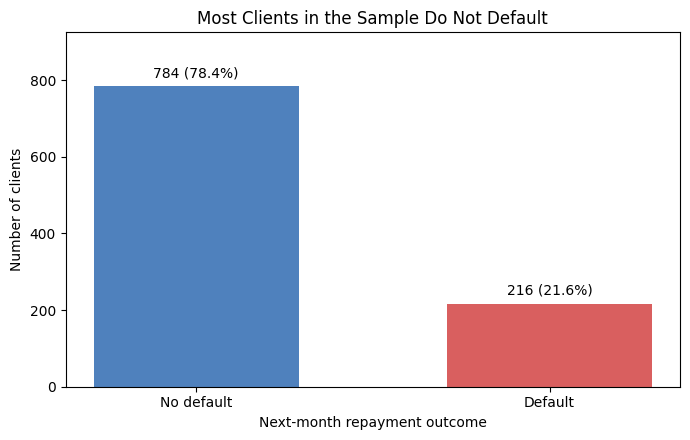

In [4]:
counts = df[target].value_counts().reindex([0, 1], fill_value=0)
labels = ["No default", "Default"]
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(labels, counts.values, color=["#4F81BD", "#D95F5F"], width=0.58)
ax.set_title("Most Clients in the Sample Do Not Default")
ax.set_ylabel("Number of clients")
ax.set_xlabel("Next-month repayment outcome")
ax.set_ylim(0, max(counts.values) * 1.18)
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, value + max(counts.values)*0.02,
            f"{value:,} ({value/len(df):.1%})", ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Interpretation and business implication.** The chart shows the balance between clients who default and those who do not. The sample default rate is 21.6%, so default is a minority outcome but is still frequent enough to matter for a card issuer. A bank should monitor the default group carefully while avoiding decisions based only on the overall rate, because risk may differ across repayment behaviours and client characteristics.

#### Figure 2. Credit limit by default outcome

/tmp/ipykernel_578/3074294365.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(groups, patch_artist=True, labels=["No default", "Default"],


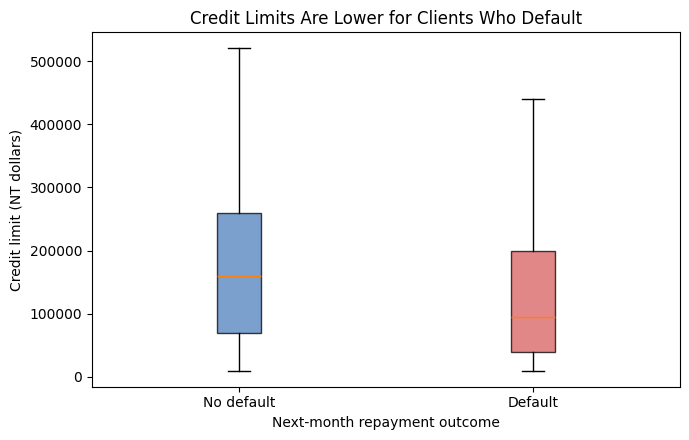

Median credit limit (no default): 160000.0
Median credit limit (default): 95000.0


In [5]:
groups = [
    df.loc[df[target] == 0, "LIMIT_BAL"],
    df.loc[df[target] == 1, "LIMIT_BAL"]
]
fig, ax = plt.subplots(figsize=(7, 4.5))
bp = ax.boxplot(groups, patch_artist=True, labels=["No default", "Default"],
                showfliers=False)
for patch, color in zip(bp["boxes"], ["#4F81BD", "#D95F5F"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
ax.set_title("Credit Limits Are Lower for Clients Who Default")
ax.set_xlabel("Next-month repayment outcome")
ax.set_ylabel("Credit limit (NT dollars)")
plt.tight_layout()
plt.show()
print("Median credit limit (no default):", df.loc[df[target] == 0, "LIMIT_BAL"].median())
print("Median credit limit (default):", df.loc[df[target] == 1, "LIMIT_BAL"].median())

**Interpretation and business implication.** The boxplots compare the distribution of credit limits between the two outcome groups. The plot suppresses individual outlier markers only to make the central distributions easier to compare; all observations remain in the statistical analysis. If the default group tends to have lower credit limits, this is an association that can motivate a formal comparison, but it does not show that changing a client's credit limit would itself cause or prevent default.

#### Figure 3. Default rate by recent repayment-delay status

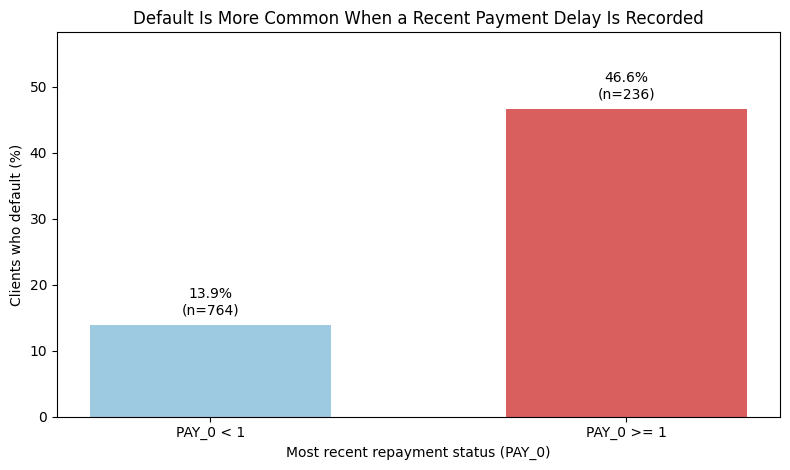

,mean,count,default_rate_percent
recent_delay,,,
No delay code >= 1 (PAY_0 < 1),0.139,764,13.874
Delay recorded (PAY_0 >= 1),0.466,236,46.610


In [6]:
df["recent_delay"] = np.where(df["PAY_0"] >= 1, "Delay recorded (PAY_0 >= 1)",
                              "No delay code >= 1 (PAY_0 < 1)")
delay_rate = df.groupby("recent_delay", observed=False)[target].agg(["mean", "count"])
order = ["No delay code >= 1 (PAY_0 < 1)", "Delay recorded (PAY_0 >= 1)"]
delay_rate = delay_rate.reindex(order)
fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(["PAY_0 < 1", "PAY_0 >= 1"], delay_rate["mean"] * 100,
              color=["#9ECAE1", "#D95F5F"], width=0.58)
ax.set_title("Default Is More Common When a Recent Payment Delay Is Recorded")
ax.set_xlabel("Most recent repayment status (PAY_0)")
ax.set_ylabel("Clients who default (%)")
ax.set_ylim(0, max(delay_rate["mean"] * 100) * 1.25)
for bar, (_, row) in zip(bars, delay_rate.iterrows()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.2,
            f"{row['mean']:.1%}\n(n={int(row['count'])})",
            ha="center", va="bottom")
plt.tight_layout()
plt.show()
display(delay_rate.assign(default_rate_percent=delay_rate["mean"]*100).round(3))

**Interpretation and business implication.** The chart compares clients with a positive recent payment-delay code (`PAY_0 >= 1`) with clients whose code is below 1. The default rate is substantially higher in the delay group in this sample. This suggests that recent repayment behaviour may be useful as an early-warning indicator. The grouping is an analytical simplification: `PAY_0 < 1` combines code -1 (payment duly) with code 0, whose meaning is not specified in the supplied documentation.

#### Figure 4. Default rate by sex code

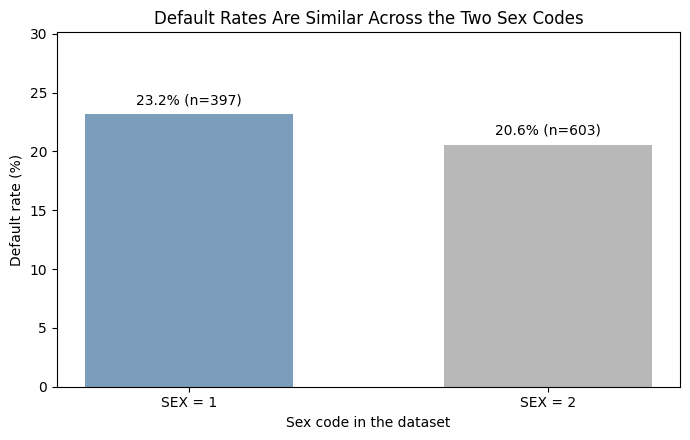

,mean,count,sum,default_rate_percent
SEX,,,,
1,0.232,397,92,23.174
2,0.206,603,124,20.564


In [7]:
sex_summary = df.groupby("SEX")[target].agg(["mean", "count", "sum"])
fig, ax = plt.subplots(figsize=(7, 4.5))
sex_labels = ["SEX = 1", "SEX = 2"]
vals = sex_summary.reindex([1, 2])["mean"] * 100
bars = ax.bar(sex_labels, vals.values, color=["#7A9EBC", "#B8B8B8"], width=0.58)
ax.set_title("Default Rates Are Similar Across the Two Sex Codes")
ax.set_xlabel("Sex code in the dataset")
ax.set_ylabel("Default rate (%)")
ax.set_ylim(0, max(vals.values)*1.3)
for bar, value, n in zip(bars, vals.values, sex_summary.reindex([1,2])["count"]):
    ax.text(bar.get_x()+bar.get_width()/2, value+0.6, f"{value:.1f}% (n={int(n)})",
            ha="center", va="bottom")
plt.tight_layout()
plt.show()
display(sex_summary.assign(default_rate_percent=sex_summary["mean"]*100).round(3))

**Interpretation and business implication.** The chart provides a descriptive comparison of default rates across the two coded sex groups. Any apparent difference should be assessed with a statistical test rather than judged from the bars alone. The codes are shown as supplied in the data; the analysis does not assume that the numerical codes themselves have a quantitative meaning.

## Part II — Research questions and statistical analysis

### 2.1 Three research questions proposed by the student before using AI

The assignment requires the student to propose three questions **without AI first**. The following are suitable draft questions based on the available variables. Before submission, confirm that these reflect the questions you personally considered before asking AI, and edit them if necessary.

1. **Do clients who default have a different average credit limit from clients who do not default?** This is relevant to credit-risk assessment and whether credit limits differ across repayment outcomes. It can be answered using `LIMIT_BAL` and the binary default variable.
2. **Is the default rate higher among clients with a positive recent repayment-delay code (`PAY_0 >= 1`) than among clients with `PAY_0 < 1`?** This is relevant to early-warning monitoring. Both groups and their default proportions can be calculated from the data.
3. **Is the default rate different between the two sex codes in the dataset?** This is relevant as a descriptive fairness-monitoring question. The data contain a coded sex variable and a binary default outcome, allowing a comparison of two proportions. Any result should be interpreted cautiously and should not be used to justify discriminatory decisions.

### 2.2 Research questions proposed by AI

**Prompt used:**

> I am analysing a sample of credit-card client data. The variables include credit limit, age, sex, education, marriage, repayment status over six months, bill amounts, payment amounts, and whether the client defaults in the next month. Propose three practical business research questions that can be answered using descriptive statistics, confidence intervals, hypothesis tests, correlation, or simple regression. For each question, identify the variables and a suitable statistical method. Avoid causal claims.

**Three AI-proposed questions:**

1. What is the population proportion of clients who default in the following month? Estimate it using a 95% confidence interval for one proportion.
2. Do clients with a positive recent repayment-delay code have a higher default proportion than clients with `PAY_0 < 1`? Use a two-proportion z-test.
3. Is the mean credit limit different between clients who default and clients who do not? Use an independent two-sample t-test, preferably Welch's version if equal variances are not assumed.

These AI suggestions are feasible because all required variables are present. The final questions below combine the business focus of the student's draft with methods suggested by AI. The AI-generated suggestions are starting points, not verified conclusions.

### 2.3 Final research questions and reasons for selection

The final three questions are:

1. **Credit limit:** Is the mean credit limit different between clients who default and clients who do not default? *(Origin: merge of the student's draft and AI suggestion.)*
2. **Recent repayment delay:** Is the default proportion higher among clients with `PAY_0 >= 1` than among clients with `PAY_0 < 1`? *(Origin: merge of the student's draft and AI suggestion.)*
3. **Sex code:** Is the default proportion different between the two sex codes? *(Origin: student's draft.)*

The first question helps describe how credit limits differ across observed default outcomes. The second has direct operational relevance because recent repayment delays may help identify clients who need earlier attention. The third checks whether the observed default proportions differ across the two recorded groups. It is included as a monitoring question, not as a basis for treating clients differently. All three questions are answerable using variables in the uploaded CSV and standard inferential methods.

### Research question 1 — Mean credit limit and default outcome

**Question:** Is the mean credit limit different between clients who default and clients who do not default?

**Hypotheses**

- \(H_0: \mu_1 - \mu_0 = 0\), where \(\mu_1\) is the population mean credit limit for clients who default and \(\mu_0\) is the population mean for clients who do not default.
- \(H_1: \mu_1 - \mu_0 \ne 0\).

**Method and justification.** Use Welch's independent two-sample t-test. The response variable, credit limit, is numerical, and the two groups consist of different clients. Welch's test does not require the two population variances to be equal.

The test statistic is

\[
t = \frac{(\bar{x}_1-\bar{x}_0)-0}
{\sqrt{s_1^2/n_1+s_0^2/n_0}},
\]

with Welch–Satterthwaite degrees of freedom. A two-sided test is appropriate because the question asks whether the means are different, without specifying a direction in advance.

In [8]:
no_default = df.loc[df[target] == 0, "LIMIT_BAL"].dropna()
default = df.loc[df[target] == 1, "LIMIT_BAL"].dropna()

welch = stats.ttest_ind(default, no_default, equal_var=False)
mean_diff = default.mean() - no_default.mean()
se_diff = np.sqrt(default.var(ddof=1)/len(default) +
                  no_default.var(ddof=1)/len(no_default))
v1 = default.var(ddof=1)/len(default)
v0 = no_default.var(ddof=1)/len(no_default)
welch_df = (v1 + v0)**2 / (v1**2/(len(default)-1) + v0**2/(len(no_default)-1))
crit = stats.t.ppf(0.975, welch_df)
ci_diff = (mean_diff - crit*se_diff, mean_diff + crit*se_diff)

print("No-default group: n =", len(no_default), "| mean =", round(no_default.mean(), 2))
print("Default group: n =", len(default), "| mean =", round(default.mean(), 2))
print("Mean difference (default - no default) =", round(mean_diff, 2))
print("95% CI for mean difference =", tuple(round(x, 2) for x in ci_diff))
print("Welch t statistic =", round(welch.statistic, 4))
print("Welch degrees of freedom =", round(welch_df, 2))
print("Two-sided p-value =", f"{welch.pvalue:.4g}")

No-default group: n = 784 | mean = 185216.84
Default group: n = 216 | mean = 133657.41
Mean difference (default - no default) = -51559.43
95% CI for mean difference = (np.float64(-69739.79), np.float64(-33379.07))
Welch t statistic = -5.5757
Welch degrees of freedom = 390.25
Two-sided p-value = 4.609e-08


**Result and business interpretation.** The sample mean credit limit is lower in the default group than in the non-default group. The Welch test evaluates whether the observed difference is compatible with equal population means. At the 5% significance level, a p-value below 0.05 leads to rejection of the null hypothesis. The confidence interval for the difference is reported as default minus non-default; an interval entirely below zero indicates a lower mean credit limit in the default group. This is an association in the sample and does not establish that a lower credit limit causes default.

### Research question 2 — Recent repayment delay and default proportion

**Question:** Is the default proportion higher among clients with `PAY_0 >= 1` than among clients with `PAY_0 < 1`?

**Hypotheses**

- \(H_0: p_1 = p_0\)
- \(H_1: p_1 > p_0\)

Here, \(p_1\) is the population default proportion for clients with `PAY_0 >= 1`, and \(p_0\) is the population default proportion for clients with `PAY_0 < 1`.

**Method and justification.** Use a two-proportion z-test. The outcome is binary and the two groups contain different clients. The test compares two independent population proportions. The pooled-proportion test statistic is

\[
z = \frac{\hat p_1-\hat p_0}
{\sqrt{\hat p(1-\hat p)(1/n_1+1/n_0)}},
\qquad
\hat p = \frac{x_1+x_0}{n_1+n_0}.
\]

A one-sided alternative is used because the question specifically asks whether the delay group has a higher default proportion.

In [9]:
delay_group = df["PAY_0"] >= 1
x1 = int(df.loc[delay_group, target].sum())
n1 = int(delay_group.sum())
x0 = int(df.loc[~delay_group, target].sum())
n0 = int((~delay_group).sum())
p1, p0 = x1/n1, x0/n0

z_stat, p_two_sided = proportions_ztest([x1, x0], [n1, n0], alternative="larger")
# Wilson intervals are reported for each group as descriptive 95% intervals.
ci1 = proportion_confint(x1, n1, alpha=0.05, method="wilson")
ci0 = proportion_confint(x0, n0, alpha=0.05, method="wilson")

print(f"PAY_0 >= 1: {x1}/{n1} = {p1:.3%}")
print(f"PAY_0 < 1:  {x0}/{n0} = {p0:.3%}")
print("95% Wilson CI, PAY_0 >= 1:", tuple(round(v, 4) for v in ci1))
print("95% Wilson CI, PAY_0 < 1:", tuple(round(v, 4) for v in ci0))
print("z statistic =", round(z_stat, 4))
print("One-sided p-value =", f"{p_two_sided:.4g}")

PAY_0 >= 1: 110/236 = 46.610%
PAY_0 < 1:  106/764 = 13.874%
95% Wilson CI, PAY_0 >= 1: (0.4035, 0.5298)
95% Wilson CI, PAY_0 < 1: (0.116, 0.1651)
z statistic = 10.6817
One-sided p-value = 6.198e-27


**Result and business interpretation.** Compare the two observed default proportions and the one-sided p-value with the 5% significance level. If the p-value is below 0.05, reject the null hypothesis in favour of a higher default proportion in the `PAY_0 >= 1` group. This would support using recent repayment delay as a risk-monitoring signal. It does not prove that a delay code alone causes a later default, and `PAY_0 < 1` combines several non-positive codes.

### Research question 3 — Default proportion and sex code

**Question:** Is the default proportion different between the two sex codes?

**Hypotheses**

- \(H_0: p_1 = p_2\)
- \(H_1: p_1 \ne p_2\)

Here, \(p_1\) and \(p_2\) are the population default proportions for `SEX = 1` and `SEX = 2`, respectively.

**Method and justification.** Use a two-sided two-proportion z-test. The outcome is binary, the explanatory variable identifies two independent groups, and the question asks whether the proportions differ in either direction. The test statistic uses the pooled estimate:

\[
z = \frac{\hat p_1-\hat p_2}
{\sqrt{\hat p(1-\hat p)(1/n_1+1/n_2)}}.
\]

In [10]:
sex1 = df.loc[df["SEX"] == 1, target]
sex2 = df.loc[df["SEX"] == 2, target]
x1, n1 = int(sex1.sum()), len(sex1)
x2, n2 = int(sex2.sum()), len(sex2)
p1, p2 = x1/n1, x2/n2

z_stat, p_value = proportions_ztest([x1, x2], [n1, n2], alternative="two-sided")
ci_sex1 = proportion_confint(x1, n1, alpha=0.05, method="wilson")
ci_sex2 = proportion_confint(x2, n2, alpha=0.05, method="wilson")

print(f"SEX = 1: {x1}/{n1} = {p1:.3%}")
print(f"SEX = 2: {x2}/{n2} = {p2:.3%}")
print("95% Wilson CI, SEX = 1:", tuple(round(v, 4) for v in ci_sex1))
print("95% Wilson CI, SEX = 2:", tuple(round(v, 4) for v in ci_sex2))
print("Difference (SEX=1 minus SEX=2):", round(p1-p2, 4))
print("z statistic =", round(z_stat, 4))
print("Two-sided p-value =", f"{p_value:.4g}")

SEX = 1: 92/397 = 23.174%
SEX = 2: 124/603 = 20.564%
95% Wilson CI, SEX = 1: (0.1929, 0.2757)
95% Wilson CI, SEX = 2: (0.1753, 0.2397)
Difference (SEX=1 minus SEX=2): 0.0261
z statistic = 0.9813
Two-sided p-value = 0.3264


**Result and business interpretation.** At the 5% significance level, reject the null hypothesis only if the two-sided p-value is below 0.05. If it is not below 0.05, the sample does not provide sufficient evidence of a difference in the two population default proportions; this is not proof that the proportions are exactly equal. This comparison is included for monitoring and should not be interpreted as evidence that sex causes default or as a justification for discriminatory credit decisions.

### Part II overall conclusion

The three analyses examine different aspects of credit risk: the average credit limit across default outcomes, the default proportion across recent repayment-delay groups, and the default proportion across the two sex codes. The results should be interpreted as statistical associations in this sample. A statistically significant result does not establish causation, and a non-significant result does not prove that there is no difference. The sample contains 1,000 records, so conclusions should not be generalised beyond the population represented by the sampling process without further information about how the sample was selected.

## Part III — Human–AI partnership reflective essay

### 3.1 Learning Python when AI can generate code

Before this course, I had learned Python in a first-year undergraduate course. I had reached the stage of using basic plotting functions, such as `plot`, but I was not yet confident in carrying out a complete data-analysis project independently. Because AI tools can now generate code quickly, I sometimes wondered whether learning Python was still necessary. After using GitHub Copilot in the labs and working on this case study, I think learning Python is still important. AI can help produce code, but it does not automatically understand the purpose of the analysis or guarantee that the code is correct. For example, in this project, I still needed to check whether the target variable was coded as 0 and 1, whether `ID` should be excluded from the analysis, and whether coded repayment-status variables should be treated as ordinary numerical measurements. These decisions require understanding the data, not just generating syntax.

I also learned that statistical interpretation cannot be delegated completely to AI. A test may run successfully but still be inappropriate if its assumptions or research question do not match. I therefore need to understand what a confidence interval, a p-value, and a test statistic mean. AI is useful as an assistant, but I remain responsible for checking the analysis and explaining the results in my own words.

### 3.2 The environment I worked in

Before this course, I had used VS Code, but I did not find it very easy or efficient. I had heard of GitHub but had not used it before. Working in GitHub Codespaces was a mixture of overwhelming and convenient. It was convenient because the coding environment could be accessed through a browser and the required tools were available in one place. At the same time, there were many features and steps to understand at the beginning. One difficulty was that restarting the environment or recovering from interruptions could be time-consuming. This sometimes affected the flow of my work.

The most useful feature for me was being able to run code in notebook cells and see the output close to the code. This made it easier to check data tables, descriptive statistics, and plots step by step. It also helped me identify which part of the analysis caused an error instead of running a long script all at once.

### 3.3 My judgement in this case study

#### 3.3.1 A working belief I tested

At the beginning, I expected that clients who defaulted would generally have higher recent repayment-delay codes than clients who did not default. I examined the distribution of `PAY_0` and compared the default rates between clients with `PAY_0 >= 1` and those with `PAY_0 < 1`. The default rate was much higher in the first group. This supported my initial expectation in this sample. However, I also learned that the grouping simplifies the original repayment-status codes, so it should be treated as a useful exploratory comparison rather than a complete description of every repayment situation. This matters because a business conclusion should reflect exactly how the variables were defined.

#### 3.3.2 A Copilot suggestion I evaluated

**Student must complete this paragraph using a real Copilot interaction. Do not submit the bracketed prompts as if they were actual events.**

I asked Copilot: **[insert the actual question or instruction you gave Copilot]**. Copilot suggested: **[describe one specific suggestion about code, a plot, a statistical test, or an interpretation that is not one of the research-question suggestions in Part II]**. I evaluated this suggestion by **[explain what you checked, such as the variable definition, the output, the formula, the assumptions, or whether the graph represented the data correctly]**. I decided to **[state what you kept or changed]** because **[give your reason]**. This experience showed me that a suggestion from Copilot should be treated as something to test rather than something to accept automatically.

#### 3.3.3 Overall effect of Copilot

Overall, Copilot helped me work faster, especially when drafting repetitive pandas operations, plotting commands, and parts of the statistical code. It was useful when I could describe the task clearly and then adapt the generated code to my data. It also helped me explore alternative ways to present the same information. However, faster code generation did not always mean faster completion. I still had to inspect the output, correct errors, and make sure that the code matched the research question. In some cases, understanding why an error occurred took more time than writing the original code.

Copilot increased my confidence in trying unfamiliar coding tasks because I had a starting point instead of having to write everything from scratch. At the same time, I became more aware that confidence should come from checking the result, not simply from seeing code run without an error. This case study has changed my view of AI-assisted programming: Python knowledge is still necessary because it allows me to judge, adapt, and explain AI-generated work. The most effective approach is to combine AI's speed with my own understanding of the data and statistical methods.

## Part IV — References

1. Kaggle. *Default of Credit Card Clients Dataset*. https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset
2. MATH7810 Python for Data Science. *Individual Case Study (AY2026/27): Instructions*.
3. MATH7810 Python for Data Science. *Week 08: Case Study — Structural Demo*.

The analysis was conducted using the CSV file supplied for this case study. The Kaggle reference is included as requested in the assignment instructions.

---

## Submission checklist

- [ ] Confirm that the three questions in Section 2.1 genuinely reflect the questions considered before using AI.
- [ ] Replace the bracketed text in Part III, Section 3.3.2 with a real Copilot example and your evaluation.
- [ ] Read every interpretation and ensure you can explain the statistical methods and results.
- [ ] Run all cells from top to bottom and check that every output and figure is visible.
- [ ] Rename the notebook and ZIP file using the required format: `[student number]_[full name without spaces].ipynb` and `.zip`.
- [ ] Zip the Jupyter Notebook only. Do not include the CSV or other documents in the ZIP.